<a href="https://colab.research.google.com/github/Maddox159-crypto/2026_ESAA_assignment/blob/main/%ED%95%84%EC%82%AC35.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

[개념]

<h3>1. 데이터 준비</h3>
<ul>
  <li><b>Fashion-MNIST</b>: 28&times;28 흑백 의류 이미지 7만 개(훈련 6만 / 테스트 1만), 레이블 0~9의 10개 클래스</li>
  <li><b>device</b>: GPU가 있으면 cuda, 없으면 cpu. 모델과 데이터는 반드시 같은 장치에 있어야 함</li>
  <li><b>FashionMNIST()</b>: download=True로 내려받고, train=False면 테스트셋, ToTensor()로 0~1 텐서 변환</li>
  <li><b>DataLoader</b>: 데이터를 배치(100개) 단위로 묶어서 불러옴</li>
  <li><b>시각화</b>: train_dataset[i]는 (이미지, 레이블) 튜플, [i][0][0, :, :]로 28&times;28 이미지만 꺼내 출력</li>
</ul>

<h3>2. 심층 신경망(DNN)과 학습</h3>
<ul>
  <li><b>모델 클래스</b>: nn.Module 상속, __init__()에 층 정의, forward()에 순전파 작성</li>
  <li><b>구조</b>: 784 → Linear 256 → ReLU → Dropout → Linear 128 → ReLU → Linear 10</li>
  <li><b>view(-1, 784)</b>: 28&times;28 이미지를 784 길이 벡터로 펼침</li>
  <li><b>Dropout(p)</b>: 학습 중 확률 p로 값을 0으로 만들어 과적합 방지</li>
  <li><b>nn.ReLU vs F.relu</b>: nn은 클래스(__init__에 정의), F는 함수(forward에서 호출)</li>
  <li><b>손실·옵티마이저</b>: CrossEntropyLoss(다중 분류), Adam(lr=0.001)</li>
  <li><b>학습 순서</b>: 순전파 → 손실 계산 → zero_grad() → backward() → step()</li>
  <li><b>평가</b>: torch.max(outputs, 1)[1]로 예측 클래스를 구해 정확도 계산. model.eval(), torch.no_grad()로 평가 후 model.train()으로 복귀</li>
  <li><b>결과</b>: 정확도 약 86%</li>
</ul>

<h3>3.합성곱 신경망(CNN)</h3>
<ul>
  <li><b>nn.Sequential</b>: 여러 층을 순서대로 묶는 컨테이너</li>
  <li><b>Conv2d</b>: 필터로 이미지 특징 추출. in_channels(입력 채널), out_channels(필터 수), kernel_size(필터 크기), padding(가장자리 0 채우기)</li>
  <li><b>BatchNorm2d</b>: 배치마다 평균·분산으로 정규화해 학습 안정화</li>
  <li><b>MaxPool2d</b>: 영역 내 최댓값만 남겨 크기 축소 (2&times;2, stride 2면 절반)</li>
  <li><b>출력 크기</b>: Conv는 (W − F + 2P)/S + 1, Pool은 (W − F)/S + 1</li>
</ul>

<ul>
  <li><b>결과</b>: 정확도 약 89%로 DNN보다 높음. 이미지가 복잡할수록 CNN의 특징 추출 능력이 중요해짐</li>
</ul>

[필사]

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.autograd import Variable
import torch.nn.functional as F
import torchvision
import torchvision.transforms as transforms
from torch.utils.data import Dataset, DataLoader

In [2]:
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")

In [3]:
train_dataset = torchvision.datasets.FashionMNIST(root='.../chap05/data', download=True,
                                           transform=transforms.Compose([transforms.ToTensor()]))
test_dataset = torchvision.datasets.FashionMNIST(root='.../chap05/data',
                                          download=True,train=False,
                                          transform=transforms.Compose([transforms.ToTensor()]))

100%|██████████| 26.4M/26.4M [00:01<00:00, 13.2MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 209kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.89MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 39.7MB/s]


In [4]:
train_loader = torch.utils.data.DataLoader(train_dataset,
                                           batch_size=100)
test_loader = torch.utils.data.DataLoader(test_dataset,
                                          batch_size=100)

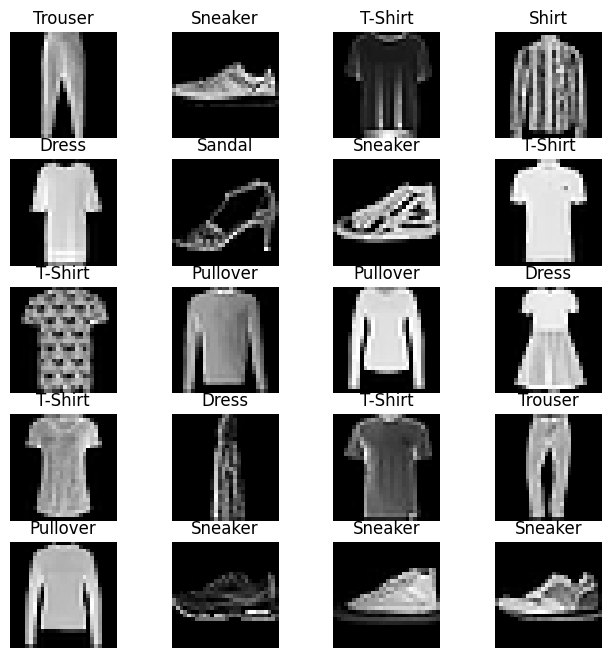

In [5]:
labels_map = {0: 'T-Shirt', 1: 'Trouser', 2: 'Pullover', 3: 'Dress', 4: 'Coat',
              5: 'Sandal', 6: 'Shirt', 7: 'Sneaker', 8: 'Bag', 9: 'Ankle Boot'}
fig = plt.figure(figsize=(8, 8))
columns = 4;
rows = 5;
for i in range(1, columns*rows +1):
    img_xy = np.random.randint(len(train_dataset))
    img = train_dataset[img_xy][0][0,:,:]
    fig.add_subplot(rows, columns, i)
    plt.title(labels_map[train_dataset[img_xy][1]])
    plt.axis('off')
    plt.imshow(img, cmap='gray')
plt.show()

In [16]:
class FashionDNN(nn.Module):
    def __init__(self):
        super(FashionDNN, self).__init__()
        self.fc1 = nn.Linear(in_features=784, out_features=256)
        self.drop = nn.Dropout(0.25)
        self.fc2 = nn.Linear(in_features=256, out_features=128)
        self.fc3 = nn.Linear(in_features=128, out_features=10)

    def forward(self, input_data):
        out = input_data.view(-1, 784)
        out = F.relu(self.fc1(out))
        out = self.drop(out)
        out = F.relu(self.fc2(out))
        out = self.fc3(out)
        return out

In [17]:
learning_rate = 0.001;
model = FashionDNN();
model.to(device)

criterion = nn.CrossEntropyLoss();
optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)
print(model)

FashionDNN(
  (fc1): Linear(in_features=784, out_features=256, bias=True)
  (drop): Dropout(p=0.25, inplace=False)
  (fc2): Linear(in_features=256, out_features=128, bias=True)
  (fc3): Linear(in_features=128, out_features=10, bias=True)
)


In [22]:
num_epochs = 5
count = 0
loss_list = []
iteration_list = []
accuracy_list = []

predictions_list = []
labels_list = []

for epoch in range(num_epochs):
    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)

        train = Variable(images.view(100, 1, 28, 28))
        labels = Variable(labels)

        outputs = model(train)
        loss = criterion(outputs, labels)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        count += 1

        if not (count % 50):
            total = 0
            correct = 0
            for images, labels in test_loader:
                images, labels = images.to(device), labels.to(device)
                labels_list.append(labels)
                test = Variable(images.view(100, 1, 28, 28))
                outputs = model(test)
                predictions = torch.max(outputs, 1)[1].to(device)
                predictions_list.append(predictions)
                correct += (predictions == labels).sum()
                total += len(labels)

            accuracy = correct * 100 / total
            loss_list.append(loss.data)
            iteration_list.append(count)
            accuracy_list.append(accuracy)

        if not (count % 500):
            print("Iteration: {}, Loss: {}, Accuracy: {}%".format(count, loss.data, accuracy))

Iteration: 500, Loss: 0.20236705243587494, Accuracy: 90.70999908447266%
Iteration: 1000, Loss: 0.2361704260110855, Accuracy: 89.98999786376953%
Iteration: 1500, Loss: 0.13587655127048492, Accuracy: 89.79999542236328%
Iteration: 2000, Loss: 0.19491277635097504, Accuracy: 89.30999755859375%
Iteration: 2500, Loss: 0.09893625229597092, Accuracy: 90.22999572753906%
Iteration: 3000, Loss: 0.16844576597213745, Accuracy: 90.58999633789062%


In [23]:
class FashionCNN(nn.Module):
    def __init__(self):
        super(FashionCNN, self).__init__()
        self.layer1 = nn.Sequential(
            nn.Conv2d(in_channels=1, out_channels=32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2)
        )
        self.layer2 = nn.Sequential(
            nn.Conv2d(in_channels=32, out_channels=64, kernel_size=3),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )
        self.fc1 = nn.Linear(in_features=64*6*6, out_features=600)
        self.drop = nn.Dropout2d(0.25)
        self.fc2 = nn.Linear(in_features=600, out_features=120)
        self.fc3 = nn.Linear(in_features=120, out_features=10)

    def forward(self, x):
        out = self.layer1(x)
        out = self.layer2(out)
        out = out.view(out.size(0), -1)
        out = self.fc1(out)
        out = self.drop(out)
        out = self.fc2(out)
        out = self.fc3(out)
        return out

In [24]:
learning_rate = 0.001;
model = FashionCNN();
model.to(device)

criterion = nn.CrossEntropyLoss();
optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate);
print(model)

FashionCNN(
  (layer1): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (layer2): Sequential(
    (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1))
    (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (fc1): Linear(in_features=2304, out_features=600, bias=True)
  (drop): Dropout2d(p=0.25, inplace=False)
  (fc2): Linear(in_features=600, out_features=120, bias=True)
  (fc3): Linear(in_features=120, out_features=10, bias=True)
)


In [25]:
num_epochs = 5
count = 0
loss_list = []
iteration_list = []
accuracy_list = []

predictions_list = []
labels_list = []

for epoch in range(num_epochs):
    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)

        train = Variable(images.view(100, 1, 28, 28))
        labels = Variable(labels)

        outputs = model(train)
        loss = criterion(outputs, labels)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        count += 1

        if not (count % 50):
            total = 0
            correct = 0
            for images, labels in test_loader:
                images, labels = images.to(device), labels.to(device)
                labels_list.append(labels)
                test = Variable(images.view(100, 1, 28, 28))
                outputs = model(test)
                predictions = torch.max(outputs, 1)[1].to(device)
                predictions_list.append(predictions)
                correct += (predictions == labels).sum()
                total += len(labels)

            accuracy = correct * 100 / total
            loss_list.append(loss.data)
            iteration_list.append(count)
            accuracy_list.append(accuracy)

        if not (count % 500):
            print("Iteration: {}, Loss: {}, Accuracy: {}%".format(count, loss.data, accuracy))

Iteration: 500, Loss: 0.5250411033630371, Accuracy: 87.69999694824219%
Iteration: 1000, Loss: 0.2998284697532654, Accuracy: 88.08999633789062%
Iteration: 1500, Loss: 0.2784656286239624, Accuracy: 89.55999755859375%
Iteration: 2000, Loss: 0.1570095270872116, Accuracy: 89.44999694824219%
Iteration: 2500, Loss: 0.18937915563583374, Accuracy: 89.23999786376953%
Iteration: 3000, Loss: 0.1406511515378952, Accuracy: 90.75999450683594%
